In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(
     accuracy_score,
     confusion_matrix,
     classification_report,
     ConfusionMatrixDisplay
)

In [3]:
df = sns.load_dataset("titanic")
print(df.head())

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  


In [4]:
#Understand the dataset before training

print("Dataset shape: ",df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
print(df.describe())

print("\nSurvival counts:")
print(df["survived"].value_counts())

print("\nSurvival percentages:")
print(df["survived"].value_counts(normalize=True) * 100)

Dataset shape:  (891, 15)

Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

Data types:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Missing values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Duplicate rows: 107

Statistical summary:
         survived      pclass         age       sibsp       parch   

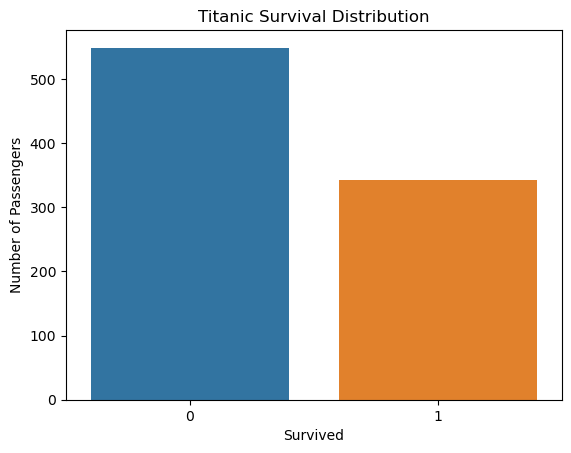

In [5]:
#plo target distribution
sns.countplot(data=df, x="survived")
plt.title("Titanic Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()

In [6]:
#Select the columns that the model will use an input
features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features]
y = df["survived"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

Input features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target values:
0    0
1    1
2    1
3    1
4    0
Name: survived, dtype: int64


In [10]:
#Indentify numerical and Categorical columns

numeric_features = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
]

categorical_features = [
    "sex",
    "embarked"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical features: ['sex', 'embarked']


In [11]:
#divide the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 42,
    stratify = y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (712, 7)
Testing data shape: (179, 7)
Training target shape: (712,)
Testing target shape: (179,)


In [12]:
#Handle missing values and encode categorical data
numeric_pipeline = Pipeline(
    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_pipeline = Pipeline(
    steps = [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers = [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [22]:
#Create and train Decision Tree model
random_forest = RandomForestClassifier(
    n_estimators = 200,
    criterion = "gini",
    max_depth = None,
    min_samples_split = 2,
    min_samples_leaf = 2,
    max_features = "sqrt",
    bootstrap = True,
    random_state = 42
)

model = Pipeline(
    steps = [
        ("preprocessor", preprocessor),
        ("classifier", random_forest)
    ]
)

model.fit(X_train, y_train)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [15]:
#Make prediction
y_pred = model.predict(X_test)
print("Predicted values:")
print(y_pred[:20])

Predicted values:
[0 0 0 0 1 0 1 1 0 0 0 0 0 0 0 0 0 0 0 1]


In [16]:
# accuracy

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy(%):", accuracy * 100)

Accuracy: 0.8100558659217877
Accuracy(%): 81.00558659217877


In [17]:
#confusion matrix

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[101   9]
 [ 25  44]]


In [18]:
#classification report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Did Not Survive",
            "Survived"
        ],
        zero_division = 0
    )
)

                 precision    recall  f1-score   support

Did Not Survive       0.80      0.92      0.86       110
       Survived       0.83      0.64      0.72        69

       accuracy                           0.81       179
      macro avg       0.82      0.78      0.79       179
   weighted avg       0.81      0.81      0.80       179



In [19]:
#feature importance

trained_forest = model.named_steps["classifier"]
trained_preprocessor = model.named_steps["preprocessor"]
feature_names = trained_preprocessor.get_feature_names_out()
importance_values = trained_forest.feature_importances_

importance_df = pd.DataFrame({
    "Feature" : feature_names,
    "Importance" : importance_values
})

importance_df = importance_df.sort_values(
    by = "Importance",
    ascending = False
)

print(importance_df)

                   Feature  Importance
4            numeric__fare    0.216440
6    categorical__sex_male    0.198799
1             numeric__age    0.184930
5  categorical__sex_female    0.180613
0          numeric__pclass    0.108826
2           numeric__sibsp    0.039524
3           numeric__parch    0.033018
9  categorical__embarked_S    0.018111
7  categorical__embarked_C    0.012547
8  categorical__embarked_Q    0.007192


<function matplotlib.pyplot.show(close=None, block=None)>

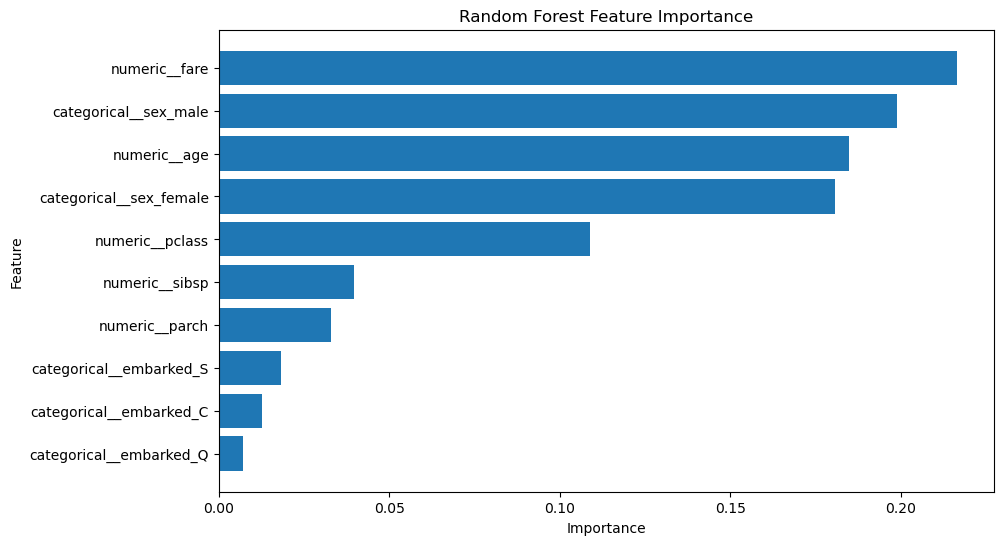

In [20]:
#feature importance plot

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.show

In [21]:
#predict a new passenger

new_passenger = pd.DataFrame({
    "pclass" : [3],
    "sex" : ["male"],
    "age" : [25],
    "sibsp" : [0],
    "parch" : [0],
    "fare" : [7.25],
    "embarked": ["S"]
})

prediction = model.predict(new_passenger)

probability = model.predict_proba(new_passenger)

print("Prediction:", prediction[0])
print("Probability of Did not Survived:", probability[0][0])
print("Probability of Survived:", probability[0][1])

Prediction: 0
Probability of Did not Survived: 0.9253692045960578
Probability of Survived: 0.07463079540394212
